In [1]:
# ---------------------------------------------------------
# Practical 3E: ECG Anomaly Detection
# Using Dense Autoencoder
# ---------------------------------------------------------

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Step 2: Load the ECG dataset

data = pd.read_csv("ecg.csv", header=None)

print("Dataset Shape:", data.shape)
print("\nFirst five records:")
print(data.head())

Dataset Shape: (4998, 141)

First five records:
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       13

In [3]:
# Step 3: Separate features and labels

# First 140 columns contain ECG signal values
X = data.iloc[:, :-1].values

# Last column contains class labels
y = data.iloc[:, -1].values.astype(int)

print("\nECG Feature Shape:", X.shape)
print("Class Distribution:")
print(pd.Series(y).value_counts())

# Class 1 = Normal
# Class 0 = Anomaly
NORMAL_LABEL = 1



ECG Feature Shape: (4998, 140)
Class Distribution:
1    2919
0    2079
Name: count, dtype: int64


In [4]:
# Step 4: Split data into training and testing sets

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
# Step 5: Select only normal records for training

X_train_normal = X_train_all[
    y_train_all == NORMAL_LABEL
]


In [6]:
# Split normal training data into training and validation

X_train_normal, X_val_normal = train_test_split(
    X_train_normal,
    test_size=0.1,
    random_state=42
)

print("\nNormal Training Shape:", X_train_normal.shape)
print("Normal Validation Shape:", X_val_normal.shape)
print("Testing Shape:", X_test.shape)



Normal Training Shape: (2101, 140)
Normal Validation Shape: (234, 140)
Testing Shape: (1000, 140)


In [9]:
# Step 6: Normalize the data

scaler = MinMaxScaler()

# Fit scaler on normal training data
X_train_normal = scaler.fit_transform(X_train_normal)

# Transform validation and testing data
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

In [10]:
# Step 7: Build Dense Autoencoder

model = keras.Sequential([

    layers.Input(shape=(140,)),

    # Encoder
    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    # Decoder
    layers.Dense(32, activation="relu"),

    layers.Dense(64, activation="relu"),

    # Reconstruct original 140 features
    layers.Dense(140, activation="sigmoid")
])

In [11]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,388 (91.36 KB)

 Trainable params: 23,388 (91.36 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 8: Compile the model

model.compile(
    optimizer="adam",
    loss="mse"
)

In [13]:
# Step 9: Train the Autoencoder using normal data

history = model.fit(
    X_train_normal,
    X_train_normal,

    epochs=20,
    batch_size=64,

    validation_data=(
        X_val_normal,
        X_val_normal
    ),

    shuffle=True
)

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0194 - val_loss: 0.0146
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0103 - val_loss: 0.0108
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0081 - val_loss: 0.0084
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0064 - val_loss: 0.0067
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0049 - val_loss: 0.0055
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0042 - val_loss: 0.0049
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038 - val_loss: 0.0046
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0036 - val_loss: 0.0044
Epoch 9/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0035 - val_loss: 0.0042
Epoch 10/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0033 - val_loss: 0.0040
Epoch 11/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0031 - val_loss: 0.0038
Epoch 12/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0029 - val_l

In [14]:
# Step 10: Calculate reconstruction error on validation data

val_reconstructed = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=1
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


In [15]:
# Set anomaly threshold
threshold = np.percentile(val_errors, 99)

print("\nAnomaly Detection Threshold:", threshold)


Anomaly Detection Threshold: 0.03064439048156558


In [16]:
# Step 11: Calculate reconstruction error on test data

test_reconstructed = model.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_reconstructed),
    axis=1
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [17]:
# Step 12: Detect anomalies

# Error greater than threshold = Anomaly
y_pred = (test_errors > threshold).astype(int)

In [18]:
# Convert actual labels:
# Normal = 0
# Anomaly = 1

y_test_anomaly = (
    y_test != NORMAL_LABEL
).astype(int)


In [19]:
# Step 13: Evaluate the model

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_anomaly, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test_anomaly,
        y_pred,
        zero_division=0
    )
)

print("Precision:", precision_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_anomaly, y_pred, zero_division=0
))


Confusion Matrix:
[[583   1]
 [374  42]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       584
           1       0.98      0.10      0.18       416

    accuracy                           0.62      1000
   macro avg       0.79      0.55      0.47      1000
weighted avg       0.76      0.62      0.52      1000

Precision: 0.9767441860465116
Recall: 0.10096153846153846
F1 Score: 0.1830065359477124


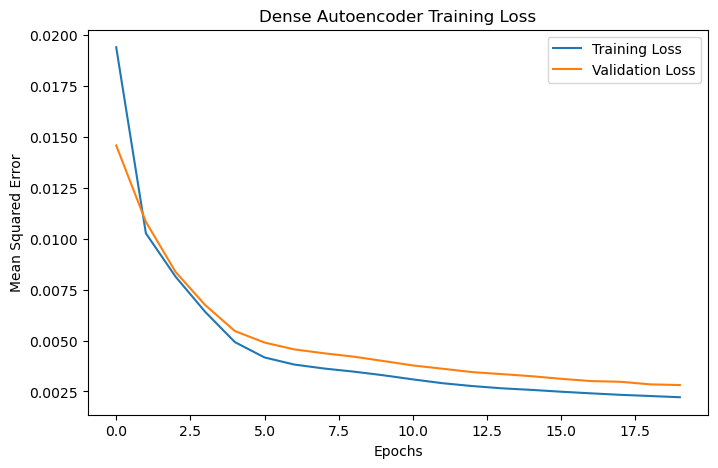

In [20]:
# Step 14: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Dense Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()

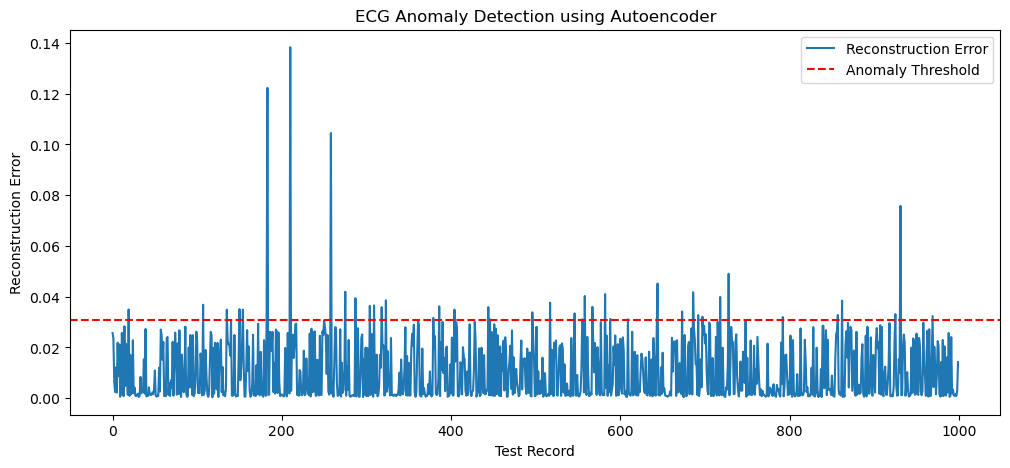

In [21]:
# Step 15: Plot reconstruction errors and threshold

plt.figure(figsize=(12, 5))

plt.plot(
    test_errors,
    label="Reconstruction Error"
)

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("ECG Anomaly Detection using Autoencoder")
plt.xlabel("Test Record")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

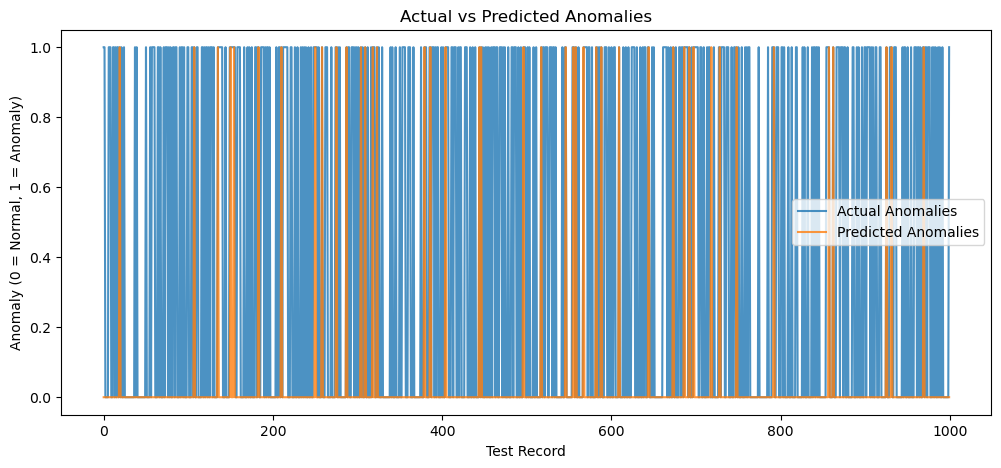

In [22]:
# Step 16: Compare actual and predicted anomalies

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_anomaly,
    label="Actual Anomalies",
    alpha=0.8
)

plt.plot(
    y_pred,
    label="Predicted Anomalies",
    alpha=0.8
)

plt.title("Actual vs Predicted Anomalies")
plt.xlabel("Test Record")
plt.ylabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.legend()
plt.show()

In [23]:
# Step 17: Display final results

print("\nTotal Test Records:", len(y_test_anomaly))
print("Actual Anomalies:", np.sum(y_test_anomaly))
print("Predicted Anomalies:", np.sum(y_pred))

print("\nPractical Completed Successfully!")



Total Test Records: 1000
Actual Anomalies: 416
Predicted Anomalies: 43

Practical Completed Successfully!
